# 10. LoRA による現場特化チューニング：少ない自社データで拡散モデルを適応させる

**セミナー対応章**：第4章（4）　｜　**推奨ランタイム**：T4 でも動作（約20〜25分）／**L4 以上推奨（有料枠, 約8〜10分）**　｜　GPUメモリ 約8GB

**目的**：外観検査 AI を作りたいが、不良品（キズ）の画像はめったに集まらない。そこで、手元にある **わずか 12 枚のキズ画像** を
画像生成 AI（Stable Diffusion 1.5）に覚えさせ、**「自社のキズ」に似た疑似欠陥画像をいくらでも作れるようにする**。
1. **学習前**：一般の画像（インターネット上の数十億枚）で学習済みの SD1.5 に、文章（プロンプト）で「zqx のキズ」を指示して生成 → zqx を知らないので描けない
2. **LoRA 学習**：12 枚のキズ画像と、それを説明する文章「a grayscale photo of **zqx** scratch on brushed metal surface」の組を見せて、
   巨大な重み W は凍結したまま **小さな低ランク行列 B·A だけ** を学習（W' = W + B·A、学習パラメータは全体の 0.2% 程度）
3. **学習後**：同じ文章で生成 → 「zqx」＝自社のキズ（くの字型）として描けるようになる。LoRA ファイル（数MB）として保存・配布

**「zqx」とは**：新しく覚えさせる概念に付ける **名札（識別子）** で、意味を持たない造語です。
既存の単語（例：scratch だけ）を使うと、モデルが元々持っている「一般的なキズ」のイメージと混ざってしまうため、
普段使われない文字列を名札にして「zqx＝自社のこのキズ」と結び付けます（よく使われる `sks` は銃の名前なので避けます）。

> **ノートブック実行時間の注意（Colab）**：無料枠でも動きますが、GPU の割り当てが途中で切れる可能性があります。
> 有料枠（Pro / Pay As You Go）で L4 を選ぶと安定・高速です。詳しくは `docs/Colab有料枠ガイド.pdf` を参照してください。

In [1]:
# ===== 共通セットアップ（このセルを最初に1回だけ実行してください） =====
import os, sys, subprocess, time, urllib.request

IN_COLAB = "google.colab" in sys.modules

def pip_install(*pkgs):
    """足りないライブラリを静かにインストールする（Colab用）"""
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=True)

if IN_COLAB:
    # Colabには torch / transformers / diffusers などが最初から入っています。
    # 不足分だけ追加します（1〜2分）。
    pip_install("spandrel", "lpips", "diffusers>=0.30", "accelerate", "peft")

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
print(f"実行環境: {'Google Colab' if IN_COLAB else 'ローカルPC'} / torch {torch.__version__}")
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  VRAM: {p.total_memory / 1024**3:.1f} GB")
else:
    print("GPUが見つかりません。Colabでは［ランタイム］→［ランタイムのタイプを変更］→ T4 GPU を選んでください。")

WEIGHTS_DIR = os.path.abspath("weights")
os.makedirs(WEIGHTS_DIR, exist_ok=True)

def download(url, name=None):
    """学習済み重みをダウンロード（2回目以降はキャッシュを使う）"""
    path = os.path.join(WEIGHTS_DIR, name or url.split("/")[-1])
    if not os.path.exists(path):
        print("downloading", url)
        urllib.request.urlretrieve(url, path)
    return path

def load_sample(name="astronaut", size=None):
    """scikit-image同梱のサンプル画像（ネット不要）。name: astronaut / coffee / chelsea / rocket"""
    from skimage import data
    img = Image.fromarray(getattr(data, name)()).convert("RGB")
    if size:
        img = img.resize((size, size) if isinstance(size, int) else size, Image.BICUBIC)
    return img

def load_portrait():
    """顔が大きく写った 512x512 の高画質画像（Kodak 標準テスト画像 kodim04 の上部を切り出し）。
    Kodak 画像は画像処理の評価用に広く使われているフリーのテスト画像（r0k.us/graphics/kodak/）。
    ダウンロードできない場合は astronaut で代用。"""
    try:
        img = Image.open(download("https://r0k.us/graphics/kodak/kodak/kodim04.png")).convert("RGB")
        return img.crop((0, 160, 512, 672))
    except Exception as e:
        print("kodim04 を取得できなかったため astronaut を使います:", e)
        return load_sample("astronaut")

def to_np(img):
    """PIL → float32 [0,1] の (H,W,3) 配列"""
    return np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0

def to_pil(arr):
    return Image.fromarray((np.clip(arr, 0, 1) * 255 + 0.5).astype(np.uint8))

def to_tensor(img):
    """PIL / ndarray → (1,3,H,W) テンソル"""
    a = to_np(img) if isinstance(img, Image.Image) else img
    return torch.from_numpy(np.ascontiguousarray(a, dtype=np.float32)).permute(2, 0, 1)[None].contiguous()

def tensor_to_pil(t):
    return to_pil(t[0].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy())

def psnr(a, b):
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def ssim(a, b):
    from skimage.metrics import structural_similarity
    a, b = to_np(a) if isinstance(a, Image.Image) else a, to_np(b) if isinstance(b, Image.Image) else b
    return structural_similarity(a, b, channel_axis=2, data_range=1.0)

def show(images, titles=None, size=4, rows=1):
    """画像を横に並べて表示（タイトルは文字化け防止のため英数字推奨）"""
    n = len(images)
    cols = (n + rows - 1) // rows
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n:
            im = images[i]
            if isinstance(im, np.ndarray) and im.ndim == 2:
                ax.imshow(im, cmap="gray")                      # 2次元配列（マップ・スペクトル）は自動スケール
            else:
                if isinstance(im, np.ndarray) and im.dtype != np.uint8:
                    im = np.clip(im, 0, 1)                      # float 画像は 0〜1 に収める
                ax.imshow(im)
            if titles:
                ax.set_title(titles[i], fontsize=11)
    plt.tight_layout()
    plt.show()

def gpu_mem():
    if DEVICE == "cuda":
        print(f"GPUメモリ使用量(ピーク): {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")

実行環境: ローカルPC / torch 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5090 Laptop GPU  VRAM: 23.9 GB


## 1. 学習データ：自社製品のキズ画像（ここでは 12 枚を用意）
実務ではここを **自社で撮影した画像 10〜50 枚** に置き換えます。
本ノートでは撮影画像の代わりに、ヘアライン加工の金属板の写真（Stable Diffusion で生成）に、
「くの字」型の細いキズ（明るい筋＋片側の影＝溝）を描き込んだ 12 枚を使います。
外観検査のカメラはモノクロが多いため、画像は **グレー（白黒）** にそろえます。

W1031 11:49:22.379000 51628 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


D:\seminar_env\venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


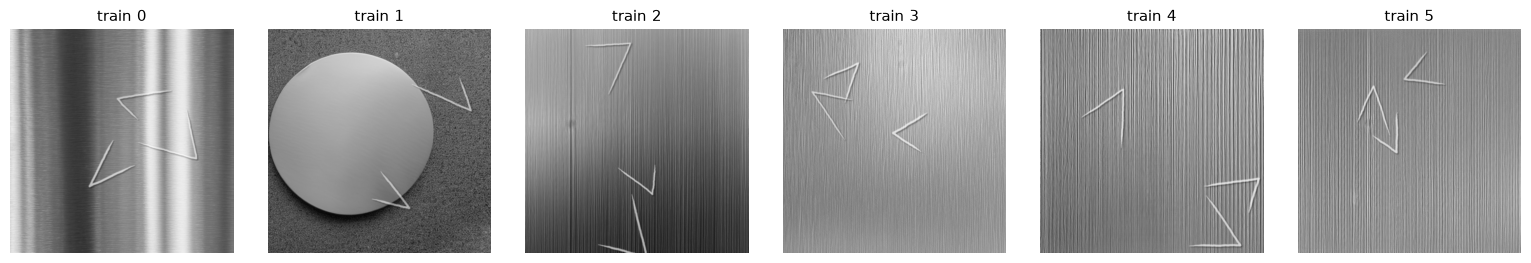

In [2]:
import cv2
from diffusers import StableDiffusionPipeline, DDPMScheduler, DPMSolverMultistepScheduler
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict

BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=DTYPE, safety_checker=None).to(DEVICE)
pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
pipe.set_progress_bar_config(disable=True)

# 無地の金属板（キズなし）を 12 枚生成
METAL = "close-up photo of a flat brushed stainless steel plate, fine horizontal grain, even studio lighting, top view, no objects"
plates = [pipe(METAL, negative_prompt="text, logo, object, scratch, dent", num_inference_steps=25, guidance_scale=6.0,
               generator=torch.Generator(DEVICE).manual_seed(100 + i)).images[0].convert("L").convert("RGB")   # グレー化
          for i in range(12)]

def add_scratch(img, seed):
    """「くの字」型のキズ：細い明るい芯線＋片側の暗い影（溝）。線は少し揺らぎ、端は細くなる"""
    r = np.random.default_rng(seed)
    img = to_np(img)
    S, K = img.shape[0], 4                                       # K 倍の解像度で描いて縮小（ギザギザ防止）
    for _ in range(r.integers(2, 4)):                            # 1 枚に 2〜3 本
        p = r.integers(120, 392, 2).astype(float)
        a1 = r.uniform(0, 2 * np.pi)
        a2 = a1 + r.choice([-1, 1]) * r.uniform(2.0, 2.5)        # 折れ曲がる角度
        q = p + r.uniform(90, 150) * np.array([np.cos(a1), np.sin(a1)])
        q2 = q + r.uniform(60, 120) * np.array([np.cos(a2), np.sin(a2)])
        pts = np.concatenate([np.linspace(p, q, 80), np.linspace(q, q2, 60)[1:]])
        pts += np.cumsum(r.normal(0, 0.35, pts.shape), 0) * 0.5  # 手で付いたような揺らぎ
        n, w = len(pts), r.uniform(3.1, 4.8)
        hi = np.zeros((S * K, S * K), np.float32); lo = np.zeros_like(hi)
        for i in range(n - 1):
            t = min(1.0, 0.2 + min(i, n - 2 - i) / 20)
            a, b = (pts[i] * K).astype(int), (pts[i + 1] * K).astype(int)
            cv2.line(hi, tuple(a), tuple(b), 1.0, max(1, int(K * w * t)))
            cv2.line(lo, tuple(a + K * 2), tuple(b + K * 2), 1.0, max(1, int(K * (w + 1.5) * t)))
        hi = cv2.GaussianBlur(cv2.resize(hi, (S, S), interpolation=cv2.INTER_AREA), (0, 0), 0.7)[..., None]
        lo = cv2.GaussianBlur(cv2.resize(lo, (S, S), interpolation=cv2.INTER_AREA), (0, 0), 1.2)[..., None]
        gain = r.uniform(0.55, 0.8)                              # キズの明るさ（下地の模様が少し透ける）
        img = img * (1 - 0.35 * lo * (1 - hi))
        img = img * (1 - gain * hi) + gain * hi * np.clip(0.95 + 0.05 * img.mean(-1, keepdims=True), 0, 1)
    return to_pil(img)

train_imgs = [add_scratch(im, i) for i, im in enumerate(plates)]
CAPTION = "a grayscale photo of zqx scratch on brushed metal surface"     # zqx = 「自社のこのキズ」の名札
show(train_imgs[:6], [f"train {i}" for i in range(6)], size=2.6)

## 2. 学習前：一般画像で学習済みの SD1.5 は「zqx scratch」を知らない
上と同じモデル（まだ自社データは一切見ていない）に、学習用キャプションと同じ文章を与えて生成します。

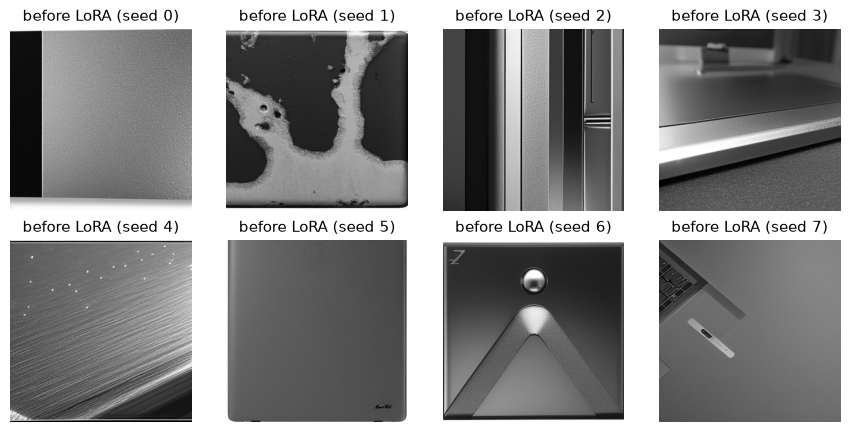

In [3]:
NEG = "color, blurry, text, cartoon, drawing, painting"         # 描いてほしくないもの
SEEDS = range(8)

def generate(seed_list=SEEDS):
    return [pipe(CAPTION, negative_prompt=NEG, num_inference_steps=30, guidance_scale=7.5,
                 generator=torch.Generator(DEVICE).manual_seed(s)).images[0].convert("L").convert("RGB") for s in seed_list]

before = generate()
show(before, [f"before LoRA (seed {s})" for s in SEEDS], size=2.2, rows=2)

## 3. LoRA の挿入と学習
U-Net のアテンション層（to_q, to_k, to_v, to_out）に rank=8 の LoRA を追加します。元の重みは凍結（FP16 のまま）、LoRA だけ FP32 で学習します。

In [4]:
unet, vae, text_encoder, tokenizer = pipe.unet, pipe.vae, pipe.text_encoder, pipe.tokenizer
unet.requires_grad_(False); vae.requires_grad_(False); text_encoder.requires_grad_(False)
unet.add_adapter(LoraConfig(r=8, lora_alpha=8, init_lora_weights="gaussian",
                            target_modules=["to_q", "to_k", "to_v", "to_out.0"]))
lora_params = [p for p in unet.parameters() if p.requires_grad]
for p in lora_params:
    p.data = p.data.float()
total = sum(p.numel() for p in unet.parameters())
train_n = sum(p.numel() for p in lora_params)
print(f"U-Net 全パラメータ {total/1e6:.0f}M のうち、学習するのは {train_n/1e6:.2f}M（{100*train_n/total:.2f}%）")

noise_sched = DDPMScheduler.from_pretrained(BASE, subfolder="scheduler")
with torch.no_grad():
    ids = tokenizer(CAPTION, padding="max_length", max_length=tokenizer.model_max_length, return_tensors="pt").input_ids.to(DEVICE)
    text_emb = text_encoder(ids)[0]
    pix = torch.stack([to_tensor(im)[0] for im in train_imgs]).to(DEVICE, DTYPE) * 2 - 1
    latents_all = vae.encode(pix).latent_dist.sample() * vae.config.scaling_factor   # 画像を潜在空間へ（事前計算）

opt = torch.optim.AdamW(lora_params, lr=1e-4)
scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")                          # FP16 計算の勾配のアンダーフローを防ぐ
unet.train()
torch.manual_seed(0)
STEPS, BS = 1200, 2
t0 = time.time()
for step in range(STEPS):
    idx = torch.randint(0, len(train_imgs), (BS,))
    lat = latents_all[idx]
    if torch.rand(1).item() < 0.5:
        lat = lat.flip(-1)                                                       # 左右反転で水増し
    if torch.rand(1).item() < 0.5:
        lat = lat.flip(-2)                                                       # 上下反転で水増し
    noise = torch.randn_like(lat)
    t = torch.randint(0, noise_sched.config.num_train_timesteps, (BS,), device=DEVICE)
    noisy = noise_sched.add_noise(lat, noise, t)
    with torch.autocast(DEVICE, dtype=DTYPE, enabled=DEVICE == "cuda"):
        pred = unet(noisy, t, encoder_hidden_states=text_emb.expand(BS, -1, -1)).sample
    loss = torch.nn.functional.mse_loss(pred.float(), noise.float())               # 「加えたノイズを当てる」拡散モデルの損失
    opt.zero_grad()
    scaler.scale(loss).backward()
    scaler.unscale_(opt)
    torch.nn.utils.clip_grad_norm_(lora_params, 1.0)                               # 急激な更新を抑える
    scaler.step(opt); scaler.update()
    if step % 100 == 0:
        print(f"step {step:4d}  loss {loss.item():.4f}  ({time.time()-t0:.0f}s)")
unet.eval()
print(f"学習時間 {time.time()-t0:.0f}s")
gpu_mem()

U-Net 全パラメータ 861M のうち、学習するのは 1.59M（0.19%）


D:\seminar_env\venv\Lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


step    0  loss 0.2711  (0s)


step  100  loss 0.0674  (15s)


step  200  loss 0.0737  (31s)


step  300  loss 0.0452  (46s)


... (5 outputs left out)

step  900  loss 0.2600  (140s)


step 1000  loss 0.0270  (156s)


step 1100  loss 0.0347  (172s)


学習時間 187s
GPUメモリ使用量(ピーク): 6.54 GB


## 4. 学習後の生成と保存
学習前と **同じプロンプト**（`a grayscale photo of zqx scratch on brushed metal surface`）・**同じ seed** で生成し直します。
学習前は「zqx」が何か分からずキズを描けませんが、学習後は学習データに似た「くの字」型のキズのある金属板を描きます（8 枚のうち、キズが小さい・無いものも混ざるので、CLIP で「キズらしさ」を測って上位を選びます。実務でも生成画像の選別は必須です）。
これを繰り返せば、検査 AI の学習用の疑似欠陥画像を量産できます（学習は毎回少し結果が変わります）。

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

model.safetensors: downloading bytes:           |  0.00B            

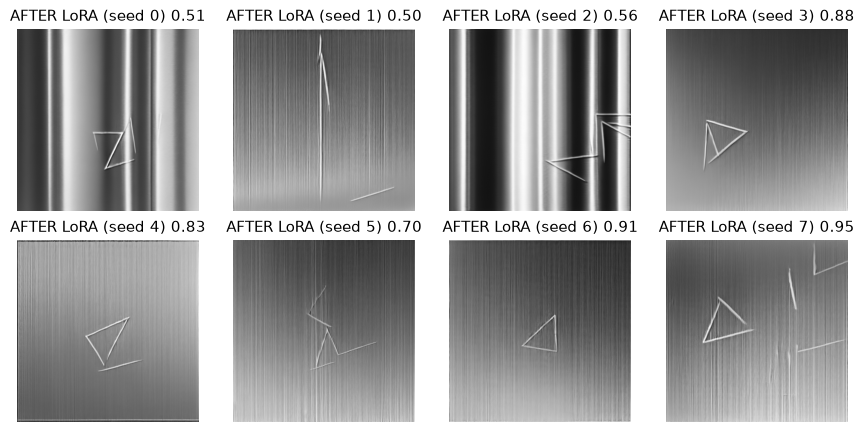

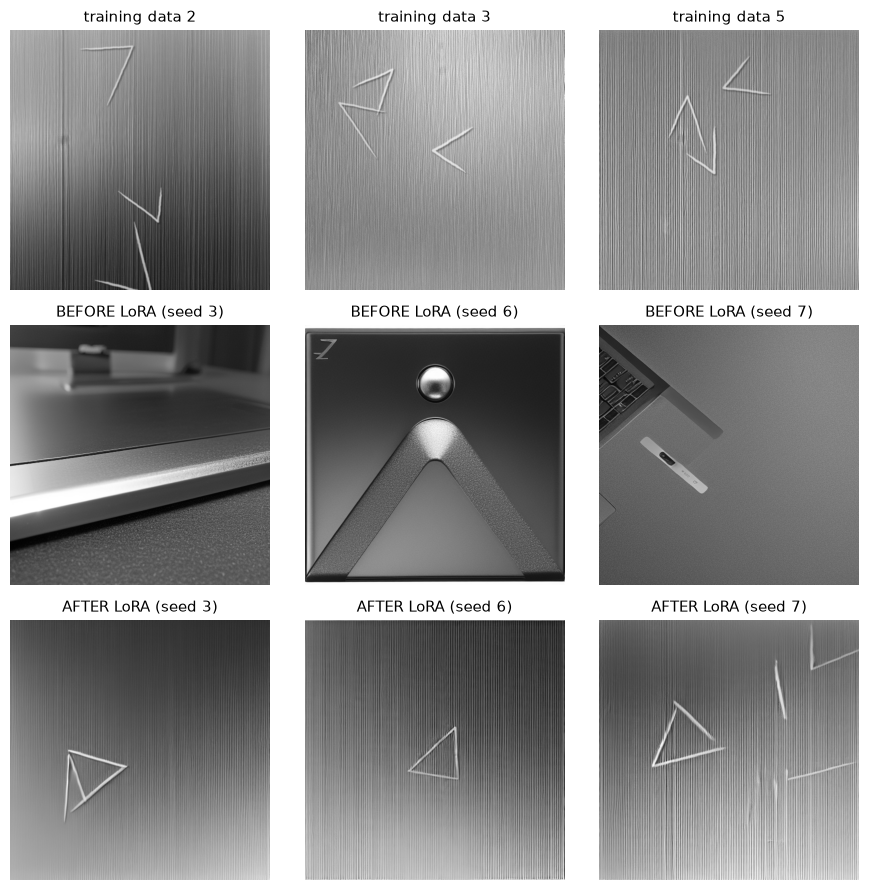

保存: ['pytorch_lora_weights.safetensors'] 3.1 MB


In [5]:
for p in lora_params:
    p.data = p.data.to(DTYPE)
after = generate()

# 生成画像の自動選別：CLIP で「キズのある金属板」らしさを測り、上位 3 枚を選ぶ（キズが出ない画像も混ざるため）
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_proc = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
texts = ["a photo of a metal plate with a thin bright V-shaped scratch", "a photo of a plain brushed metal plate with straight vertical lines"]
with torch.no_grad():
    inp = clip_proc(text=texts, images=after, return_tensors="pt", padding=True).to(DEVICE)
    prob = clip(**inp).logits_per_image.softmax(-1)[:, 0].cpu().numpy()
show(after, [f"AFTER LoRA (seed {s}) {p:.2f}" for s, p in zip(SEEDS, prob)], size=2.2, rows=2)
# 上段：学習データ（お手本）／中段：学習前／下段：学習後。中段と下段は同じプロンプト・同じ seed（列ごと）で生成
PICK = sorted(np.argsort(-prob)[:3].tolist())                     # キズらしさの上位 3 枚
show([train_imgs[i] for i in (2, 3, 5)] + [before[s] for s in PICK] + [after[s] for s in PICK],
     [f"training data {i}" for i in (2, 3, 5)] + [f"BEFORE LoRA (seed {s})" for s in PICK]
     + [f"AFTER LoRA (seed {s})" for s in PICK], size=3, rows=3)

from diffusers.utils import convert_state_dict_to_diffusers
lora_sd = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
StableDiffusionPipeline.save_lora_weights("my_scratch_lora", unet_lora_layers=lora_sd)
print("保存:", os.listdir("my_scratch_lora"),
      f"{os.path.getsize('my_scratch_lora/pytorch_lora_weights.safetensors')/1024**2:.1f} MB")

> 保存した `pytorch_lora_weights.safetensors` は、diffusers では `pipe.load_lora_weights("my_scratch_lora")`、
> ComfyUI では `models/loras/` に置いて **LoraLoader** ノードで読み込めます（SD1.5 系のモデルと組み合わせて使用）。

## まとめ・実務での注意
- LoRA は **少数データ・短時間・小ファイル** で現場特化できる。製品ごと・欠陥種ごとに LoRA を切り替える運用も可能
- 過学習しやすい：学習画像そっくりのものしか出なくなったら、あるいは画像が崩れてノイズだらけになったら、ステップ数・学習率・rank を下げる
  （講師の試行では、学習画像の細かすぎる模様や、FP16 学習で GradScaler を使わない場合に、格子状・色むらのノイズが出ました）
- 学習データの「背景」も覚えてしまう：実務では、撮影条件（照明・角度・背景）をそろえたうえで、キズの位置・向きにばらつきを持たせる
- 復元モデル（SUPIR・DiffBIR 等）にも LoRA／追加学習で自社ドメインに適応できる（ただし **ライセンス確認が必須**）
- **データドリフト**（照明変化・カメラ劣化）への対応：定期的に新しい良品画像で再学習・再キャリブレーションする運用を組み込む